In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
from sklearn.calibration import calibration_curve
import joblib

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    from sklearn.ensemble import HistGradientBoostingClassifier
    HAS_LGBM = False
print("LightGBM available:", HAS_LGBM)

sns.set_theme(style="whitegrid")
PROC = Path("../data/processed")
FIG = Path("../figures")
MODELS = Path("../models")
MODELS.mkdir(exist_ok=True)

matches = pd.read_csv(PROC / "matches.csv", dtype={"match_id": str}, parse_dates=["date"])
balls = pd.read_csv(PROC / "balls.csv", dtype={"match_id": str})

LightGBM available: True


#### Turn balls into match states

In [2]:
FEATURES = ["runs_needed", "balls_left", "wickets_left", "target", "crr", "rrr"]

def build_states(balls, match_ids, matches):
    first_inn = balls[balls["innings"] == 1].groupby("match_id")["runs_total"].sum()
    winners = matches.set_index("match_id")["winner"]

    b = balls[(balls["innings"] == 2) & balls["match_id"].isin(match_ids)].copy()
    # Rows are already in delivery order from the parser, so cumulative sums are valid
    b["target"] = b["match_id"].map(first_inn) + 1
    b["cum_runs"] = b.groupby("match_id")["runs_total"].cumsum()
    b["cum_wkts"] = b.groupby("match_id")["wicket"].cumsum()

    b["runs_needed"] = b["target"] - b["cum_runs"]
    b["balls_left"] = (300 - b["legal_ball_no"]).clip(lower=0)
    b["wickets_left"] = (10 - b["cum_wkts"]).clip(lower=0)
    b["crr"] = b["cum_runs"] * 6 / b["legal_ball_no"].clip(lower=1)
    b["rrr"] = (b["runs_needed"] * 6 / b["balls_left"].clip(lower=1)).clip(upper=36)
    b["chaser_won"] = (b["match_id"].map(winners) == b["batting_team"]).astype(int)
    return b

clean = matches[
    (matches["result"] == "win") &
    (matches["method"].isna()) &
    (matches["overs_limit"] == 50)
].copy()

states = build_states(balls, clean["match_id"], matches)
live = (states["runs_needed"] > 0) & (states["wickets_left"] > 0) & (states["balls_left"] > 0)
states = states[live]
print(f"{len(states):,} live match states from {states['match_id'].nunique()} chases")

568,776 live match states from 2230 chases


#### Time-based split by match

In [3]:
match_dates = clean.set_index("match_id")["date"]
states["date"] = states["match_id"].map(match_dates)
cutoff = clean["date"].quantile(0.8)

train = states[states["date"] < cutoff]
test = states[states["date"] >= cutoff]

assert set(train["match_id"]).isdisjoint(test["match_id"])   # no match in both
print(f"Cutoff: {cutoff.date()}")
print(f"Train: {train['match_id'].nunique()} matches, {len(train):,} states")
print(f"Test:  {test['match_id'].nunique()} matches, {len(test):,} states")

X_train, y_train = train[FEATURES], train["chaser_won"]
X_test, y_test = test[FEATURES], test["chaser_won"]

Cutoff: 2022-08-17
Train: 1783 matches, 458,935 states
Test:  447 matches, 109,841 states


#### Train both models

In [4]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)

# +1 = probability must rise with the feature, -1 = must fall, 0 = unconstrained
mono = [-1, 1, 1, 0, 0, -1]   # runs_needed, balls_left, wickets_left, target, crr, rrr

if HAS_LGBM:
    gbm = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                         min_child_samples=200, monotone_constraints=mono,
                         random_state=42, verbose=-1)
else:
    gbm = HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05,
                                         min_samples_leaf=200, monotonic_cst=mono,
                                         random_state=42)
gbm.fit(X_train, y_train)
print("Trained.")

Trained.


#### Evaluate

In [5]:
base_rate = y_train.mean()
preds = {
    "Naive baseline": np.full(len(y_test), base_rate),
    "Logistic regression": logreg.predict_proba(X_test)[:, 1],
    "Gradient boosting": gbm.predict_proba(X_test)[:, 1],
}

results = pd.DataFrame({
    name: {
        "Log loss": log_loss(y_test, p),
        "Brier": brier_score_loss(y_test, p),
        "ROC AUC": roc_auc_score(y_test, p) if p.std() > 0 else 0.5,
    }
    for name, p in preds.items()
}).T
print(results.round(4))

                     Log loss   Brier  ROC AUC
Naive baseline         0.6932  0.2500   0.5000
Logistic regression    0.4022  0.1321   0.8969
Gradient boosting      0.4673  0.1484   0.8780


#### Calibration plot

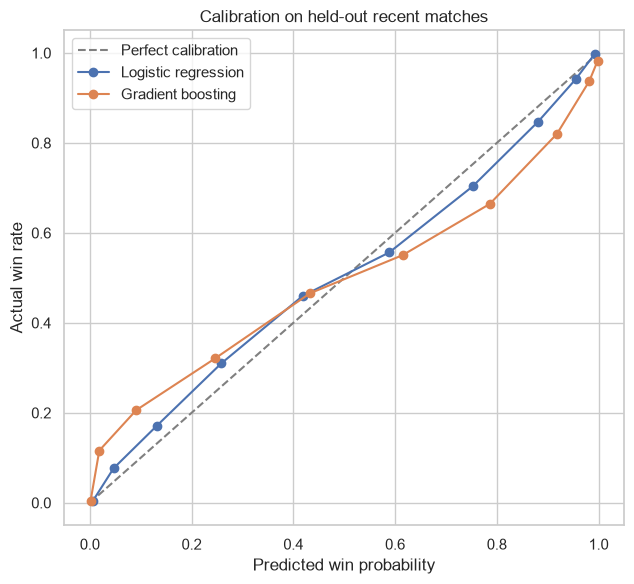

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], ls="--", color="grey", label="Perfect calibration")
for name in ["Logistic regression", "Gradient boosting"]:
    frac_pos, mean_pred = calibration_curve(y_test, preds[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.set(xlabel="Predicted win probability", ylabel="Actual win rate",
       title="Calibration on held-out recent matches")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "calibration.png", dpi=150)
plt.show()

### Win-probability curve for a real match

In [7]:
def plot_match(match_id, model, title=None, save_as=None):
    s = build_states(balls, [match_id], matches)
    s = s[(s["runs_needed"] > 0) & (s["wickets_left"] > 0)]
    p = model.predict_proba(s[FEATURES])[:, 1] * 100
    overs = s["legal_ball_no"] / 6
    chaser = s["batting_team"].iloc[0]

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(overs, p, lw=2)
    wk = s["wicket"] > 0
    ax.scatter(overs[wk], p[wk.values], color="red", zorder=3, label="Wicket")
    ax.axhline(50, ls="--", color="grey")
    ax.set(xlabel="Overs into chase", ylabel=f"{chaser} win probability (%)",
           ylim=(0, 100), title=title or f"Win probability: {chaser} chasing")
    ax.legend()
    plt.tight_layout()
    if save_as:
        plt.savefig(FIG / save_as, dpi=150)
    plt.show()

final_2019 = matches[matches["date"] == "2019-07-14"]
print(final_2019[["match_id", "team1", "team2", "result", "venue"]])

    match_id    team1        team2 result   venue
255  1144530  England  New Zealand    tie  Lord's


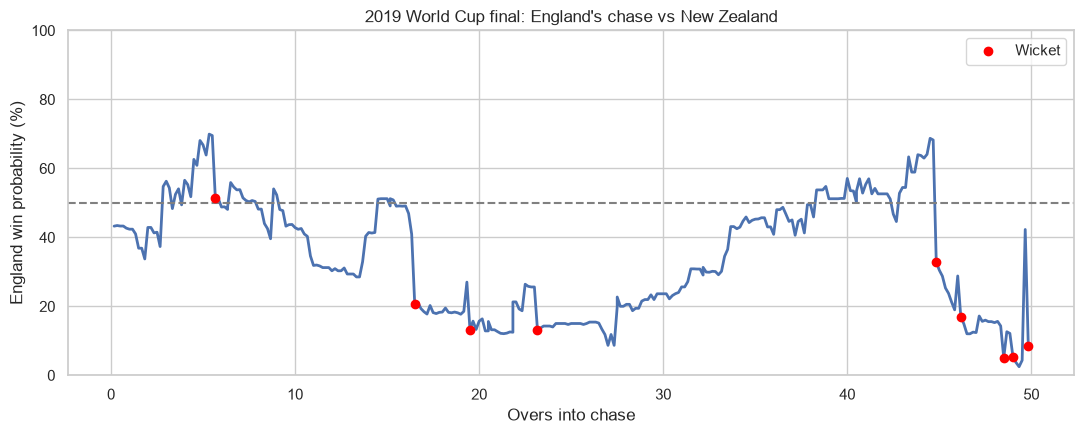

In [8]:
plot_match(final_2019["match_id"].iloc[0], gbm,
           title="2019 World Cup final: England's chase vs New Zealand",
           save_as="wp_2019_final.png")

In [10]:
#Saving the model
joblib.dump(gbm, MODELS / "win_prob_gbm.joblib")
print("Saved.")

Saved.


### Finalize with logistic regression

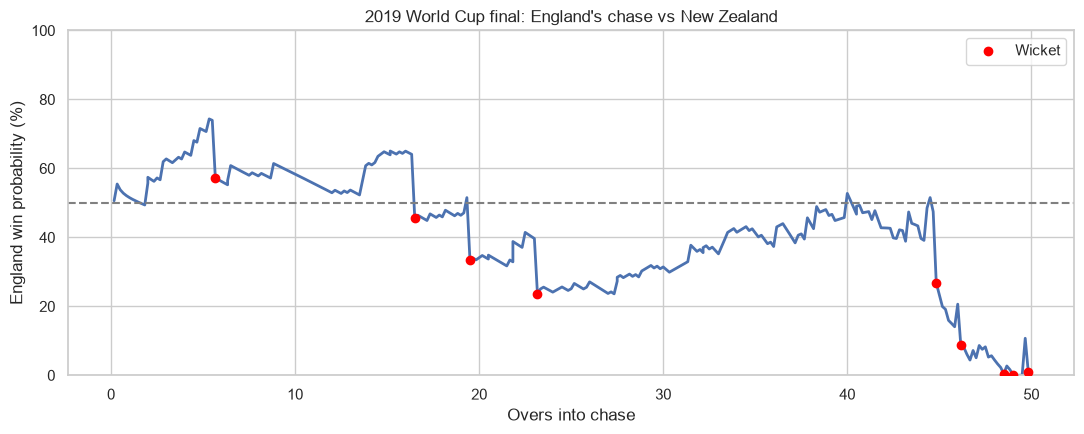

rrr            -2.246
runs_needed    -2.208
crr             0.086
balls_left      0.124
target          0.663
wickets_left    1.716
dtype: float64


In [11]:
# Final model: logistic regression (better log loss, Brier, AUC and calibration on held-out data)
plot_match(final_2019["match_id"].iloc[0], logreg,
           title="2019 World Cup final: England's chase vs New Zealand",
           save_as="wp_2019_final.png")

joblib.dump(logreg, MODELS / "win_prob_logreg.joblib")

coefs = pd.Series(logreg[-1].coef_[0], index=FEATURES).sort_values()
print(coefs.round(3))

In [13]:
def win_probability(target, score, wickets, overs):
    """Chasing team's win probability. overs uses cricket notation: 32.4 = 32 overs + 4 balls."""
    balls_bowled = int(overs) * 6 + round((overs % 1) * 10)
    balls_left = max(300 - balls_bowled, 0)
    runs_needed = target - score
    state = pd.DataFrame([{
        "runs_needed": runs_needed,
        "balls_left": balls_left,
        "wickets_left": 10 - wickets,
        "target": target,
        "crr": score * 6 / max(balls_bowled, 1),
        "rrr": min(runs_needed * 6 / max(balls_left, 1), 36),
    }])[FEATURES]
    return logreg.predict_proba(state)[0, 1]

# Example: chasing 300, at 180/4 after 35 overs
p = win_probability(target=300, score=220, wickets=4, overs=35.0)
print(f"Chasing team win probability: {p:.1%}")

Chasing team win probability: 86.3%
